PASO 1: EXPLORACION DE DATOS DE AMBOS DATASETS

In [1]:
import os
import shutil
import subprocess

SCRIPT INICIAL PARA BAJAR EL PRIMER DATASET DE KAGGLE: Driving Behavior Dataset

Se implementa ingesta mediante API con un manejo de excepciones para entornos ajenos

Definimos y creamos la carpeta destino en el proyecto

In [2]:
destino_raw = "../data/raw/dataset_kaggle"
os.makedirs(destino_raw, exist_ok=True)

Si la carpeta destino_raw está vacía, se ejecuta el bloque dentro del if

In [3]:
if len(os.listdir(destino_raw)) == 0:
    try:
        print("Intentando descargar el dataset desde Kaggle de forma automática")
        import kagglehub
        
        # Descarga a la caché del sistema
        path_cache = kagglehub.dataset_download("shashwatwork/driving-behavior-dataset")
        
        # Movemos los archivos de la caché a nuestra carpeta del proyecto
        for archivo in os.listdir(path_cache):
            origen = os.path.join(path_cache, archivo)
            destino = os.path.join(destino_raw, archivo)
            
            if os.path.isdir(origen):
                shutil.copytree(origen, destino)
            else:
                shutil.copy2(origen, destino)
                
        print(f"Descarga exitosa. Datos copiados a: {destino_raw}")
        
    except Exception as e:
        # Plan B: Mensaje claro si el que ejecuta no tiene la API Key
        print("\n" + "="*65)
        print(" No se detectó la API Key de Kaggle en este entorno. Para continuar, siga estos pasos manualmente:")
        print("  1. Ingrese a: https://www.kaggle.com/datasets/shashwatwork/driving-behavior-dataset")
        print("  2. Descargue el dataset manualmente (botón 'Download').")
        print(f"  3. Descomprima los archivos dentro de la carpeta: {destino_raw}")
        print("  4. Vuelva a ejecutar esta celda.")
        print("="*65 + "\n")
else:
    print(f"Los datos ya están listos para usarse en: {destino_raw}")

Los datos ya están listos para usarse en: ../data/raw/dataset_kaggle


SCRIPT PARA DESCARGAR EL DATASET DE GITHUB: Driver Behavior Dataset

Ruta apuntando a la raíz del proyecto

In [4]:
destino_github = "../data/raw/dataset_github"
url_repo_github = "https://github.com/jair-jr/driverBehaviorDataset.git"

Si NO existe dataset_github ejecutar el siguiente codigo de creacion y descarga del dataset

In [5]:
if not os.path.exists(destino_github):
    print("Clonando el dataset desde GitHub...")
    try:
        subprocess.run(["git", "clone", url_repo_github, destino_github], check=True)
        print(f"Descarga exitosa.Datos de GitHub copiados a: {destino_github}")
        
        # Eliminar la carpeta .git para desvincularlo del repo original
        shutil.rmtree(os.path.join(destino_github, ".git"), ignore_errors=True)
        
    except subprocess.CalledProcessError:
        print("\n" + "="*65)
        print(" No se pudo clonar el repositorio de GitHub.")
        print(f" descargue el ZIP manualmente desde: {url_repo_github}")
        print(f"Y extraiga su contenido en la carpeta: {destino_github}")
        print("="*65 + "\n")
else:
    print(f"Los datos de GitHub ya están listos en: {destino_github}")

Los datos de GitHub ya están listos en: ../data/raw/dataset_github


-------------------------------------------------------------------------------------------------------------------------

ANALISIS EXPLORATORIO DE DATOS

Analizaremos el dataset Kaggle en primer lugar

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data_profiling import ProfileReport
import numpy as np

Datos crudos (sensor_raw.csv): Contiene las series temporales originales, instante a instante. El sistema registró información del acelerómetro (ejes X, Y, Z en m/s2) y del giroscopio (ejes X, Y, Z en grados por segundo).

Datos tabulares con características (sero_features_X.csv): El resto de los archivos contienen los mismos datos, pero les aplicaron una técnica de ventanas temporales (sliding window) calculando las variables estadísticas (media, varianza, curtosis, etc.) para distintos tamaños de ventana (de 4 a 20 segundos), con el objetivo de que estas variables tengan sentido fisico asociado a una maniobra especifica . Siguiendo la documentación oficial del autor, indica que el tamaño de ventana óptimo es de 14 segundos. Por eso cargamos features_14 en df_feat para analizarla.

In [7]:
# Cargar los datasets en memoria
ruta_raw = "../data/raw/dataset_kaggle/sensor_raw.csv"
ruta_feat = "../data/raw/dataset_kaggle/features_14.csv"

df_raw = pd.read_csv(ruta_raw)
df_feat = pd.read_csv(ruta_feat)

In [8]:
df_raw.head()

,Target(Class),GyroX,GyroY,GyroZ,AccX,AccY,AccZ
0,1,-0.923664,3.694656,0.824427,0.162598,-0.086670,-0.969482
1,1,-0.908397,4.534351,0.832061,0.175781,-0.100586,-1.013184
2,1,0.786260,3.969466,0.587786,0.322754,-0.140381,-0.911621
3,1,0.335878,4.564885,-0.251908,0.480225,-0.226807,-0.936768
4,1,3.351145,2.694656,-0.106870,0.426025,-0.253906,-0.950195


7 columnas en total: 6 dedicadas a las mediciones del acelerometro y del giroscopio, y 1 dedicada al target que puede tomar valores entre 1-4. Aceleración brusca (Clase 1) Giro brusco a la derecha (Clase 2) Giro brusco a la izquierda (Clase 3) Frenada brusca (Clase 4)


- AccX aumenta progresivamente (de 0,16 g a 0,48 g), lo que evidencia una aceleración del vehículo. GyroZ permanece cercano a cero, ya que el movimiento ocurre principalmente en línea recta, sin rotación significativa sobre el eje vertical.
- El auto está acelerando en línea recta y aun así GyroY marca entre 3.7 y 4.5 °/s desde el segundo cero, tal vez por un posible sesgo del sensor. Por otro lado, AccZ se mantiene alrededor de -1 g. (y no aprox -9,8)

In [9]:
# Configuración para que Pandas no oculte columnas del dataset de features
pd.set_option('display.max_columns', None)

In [10]:
df_feat.head()

,Target,AccMeanX,AccMeanY,AccMeanZ,AccCovX,AccCovY,AccCovZ,AccSkewX,AccSkewY,AccSkewZ,AccKurtX,AccKurtY,AccKurtZ,AccSumX,AccSumY,AccSumZ,AccMinX,AccMinY,AccMinZ,AccMaxX,AccMaxY,AccMaxZ,AccVarX,AccVarY,AccVarZ,AccMedianX,AccMedianY,AccMedianZ,AccStdX,AccStdY,AccStdZ,GyroMeanX,GyroMeanY,GyroMeanZ,GyroCovX,GyroCovY,GyroCovZ,GyroSkewX,GyroSkewY,GyroSkewZ,GyroSumX,GyroSumY,GyroSumZ,GyroKurtX,GyroKurtY,GyroKurtZ,GyroMinX,GyroMinY,GyroMinZ,GyroMaxX,GyroMaxY,GyroMaxZ,GyroVarX,GyroVarY,GyroVarZ,GyroMedianX,GyroMedianY,GyroMedianZ,GyroStdX,GyroStdY,GyroStdZ
0,1,0.285339,-0.138611,-0.957764,0.022150,0.003975,0.001926,0.867594,-1.305868,-0.507254,-1.164806,1.239840,-0.761065,1.141357,-0.554443,-3.831055,0.162598,-0.226807,-1.013184,0.480225,-0.08667,-0.911621,0.022150,0.003975,0.001926,0.249268,-0.120483,-0.953125,0.148827,0.063049,0.043889,-0.177481,4.190840,0.498092,0.761120,0.184372,0.262859,0.225352,-0.338028,-1.727183,-0.709924,16.763359,1.992366,-4.710496,-4.035868,2.914796,-0.923664,3.694656,-0.251908,0.786260,4.564885,0.832061,0.761120,0.184372,0.262859,-0.286260,4.251908,0.706107,0.872422,0.429385,0.512697
1,1,0.313477,-0.161670,-0.956250,0.020571,0.005640,0.001456,0.002474,-0.395088,-0.677572,-2.649441,-2.649803,0.636762,1.567383,-0.808350,-4.781250,0.162598,-0.253906,-1.013184,0.480225,-0.08667,-0.911621,0.020571,0.005640,0.001456,0.322754,-0.140381,-0.950195,0.143425,0.075100,0.038159,0.528244,3.891603,0.377099,3.061080,0.585991,0.270340,1.282080,-1.069372,-0.501530,2.641221,19.458015,1.885496,1.633018,0.846742,-2.932893,-0.923664,2.694656,-0.251908,3.351145,4.564885,0.832061,3.061080,0.585991,0.270340,0.335878,3.969466,0.587786,1.749594,0.765501,0.519942
2,1,0.325195,-0.158325,-0.950155,0.017281,0.004579,0.001388,-0.354212,-0.603657,-0.984635,-1.819232,-1.472251,0.663006,1.951172,-0.949951,-5.700928,0.162598,-0.253906,-1.013184,0.480225,-0.08667,-0.911621,0.017281,0.004579,0.001388,0.353271,-0.140991,-0.943481,0.131455,0.067669,0.037253,0.189567,3.773537,0.038168,3.137076,0.552431,0.905518,1.309765,-0.378864,-1.302740,1.137405,22.641221,0.229008,1.663170,-1.192246,1.540639,-1.503817,2.694656,-1.656489,3.351145,4.564885,0.832061,3.137076,0.552431,0.905518,-0.286260,3.832061,0.240458,1.771179,0.743257,0.951587
3,1,0.336565,-0.172468,-0.937640,0.015305,0.005216,0.002253,-0.655653,-0.152454,-0.040530,-1.214712,-2.185485,0.666209,2.355957,-1.207275,-6.563477,0.162598,-0.257324,-1.013184,0.480225,-0.08667,-0.862549,0.015305,0.005216,0.002253,0.383789,-0.141602,-0.936768,0.123715,0.072222,0.047465,0.356598,4.480916,-0.102508,2.809524,3.963056,0.893127,0.861002,2.009707,-0.667798,2.496183,31.366412,-0.717557,0.434190,4.642007,-0.680104,-1.503817,2.694656,-1.656489,3.351145,8.725191,0.832061,2.809524,3.963056,0.893127,0.335878,3.969466,-0.106870,1.676163,1.990743,0.945054
4,1,0.337860,-0.164185,-0.941681,0.013132,0.005020,0.002062,-0.718488,-0.446061,0.250539,-0.666622,-1.909540,0.556116,2.702881,-1.313477,-7.533447,0.162598,-0.257324,-1.013184,0.480225,-0.08667,-0.862549,0.013132,0.005020,0.002062,0.365356,-0.140991,-0.943481,0.114596,0.070850,0.045406,0.176527,4.434160,-0.167939,2.667567,3.414394,0.799787,1.072055,2.151158,-0.388248,1.412214,35.473282,-1.343511,0.737750,5.422661,-0.817133,-1.503817,2.694656,-1.656489,3.351145,8.725191,0.832061,2.667567,3.414394,0.799787,-0.286260,4.038168,-0.179389,1.633269,1.847808,0.894308


61 columnas en total: 60 dedicadas a las variables estadisticas extraidas de la ventana temporal de 14 segundos del acelerometro y del giroscopio, y 1 dedicada al Target (clase)

Veamos algo del sensor crudo: Se utiliza .describe() para obtener una primera visión estadística de los datos, verificar unidades y detectar posibles problemas de calidad. El comando asume que cada fila es un individuo independiente, ignorando que son instantes de un mismo evento continuo. 
Pero solo lo ejecutaremos para revisar rapidamente los valores de min y max, y asegurarnos de que no haya por ejemplo un acelerometro marcando algun numero absurdo (9999). Ademas nos servira para observar que pasa con el eje z, que nos aporta que nos dice.

In [11]:
df_raw.describe()

,Target(Class),GyroX,GyroY,GyroZ,AccX,AccY,AccZ
count,1114.000000,1114.000000,1114.000000,1114.000000,1114.000000,1114.000000,1114.000000
mean,2.490126,-0.829957,4.122309,1.076404,0.252417,-0.095110,-0.983215
std,1.051415,3.404297,3.252790,12.049384,0.183155,0.190407,0.098061
min,1.000000,-14.946565,-10.351145,-50.259542,-0.252686,-0.793457,-1.367920
25%,2.000000,-2.274809,2.610687,0.282443,0.132202,-0.179077,-1.031372
50%,3.000000,-0.698473,4.290076,0.961832,0.244507,-0.102295,-0.986938
75%,3.000000,0.784351,5.761450,1.992366,0.372559,-0.023010,-0.928223
max,4.000000,12.778626,16.793893,45.442748,0.747803,0.768555,-0.456787


Aspectos importantes:
- Analizamos la escala de las mediciones del acelerómetro y giroscopio.
- Los picos extremos podrian representar maniobras reales (frenadas bruscas o giros agresivos), por lo que no deben eliminarse automáticamente.
- El valor máximo de AccZ es -0,456787 m/s², mientras que el mínimo es -1,367920 m/s². Es decir, todas las mediciones de AccZ son negativas y se concentran principalmente alrededor de -1 m/s². (a tener en cuenta este dato)
- No se ven valores faltantes (count), sensores sin variabilidad (std = 0) y mediciones físicamente raras. Para min y max no pareciera encontrarse algun valor extremo.
- Al resumir todas las observaciones, .describe() no conserva el orden ni permite distinguir entre estados de conducción.

Ahora lo mismo con features_14.csv / Se utiliza .describe() para analizar la distribución de las características extraídas de ventanas temporales de 14 segundos. A diferencia de las señales crudas, cada fila representa un conjunto de estadísticas calculadas sobre un intervalo de conducción.

In [12]:
df_feat.describe()

,Target,AccMeanX,AccMeanY,AccMeanZ,AccCovX,AccCovY,AccCovZ,AccSkewX,AccSkewY,AccSkewZ,AccKurtX,AccKurtY,AccKurtZ,AccSumX,AccSumY,AccSumZ,AccMinX,AccMinY,AccMinZ,AccMaxX,AccMaxY,AccMaxZ,AccVarX,AccVarY,AccVarZ,AccMedianX,AccMedianY,AccMedianZ,AccStdX,AccStdY,AccStdZ,GyroMeanX,GyroMeanY,GyroMeanZ,GyroCovX,GyroCovY,GyroCovZ,GyroSkewX,GyroSkewY,GyroSkewZ,GyroSumX,GyroSumY,GyroSumZ,GyroKurtX,GyroKurtY,GyroKurtZ,GyroMinX,GyroMinY,GyroMinZ,GyroMaxX,GyroMaxY,GyroMaxZ,GyroVarX,GyroVarY,GyroVarZ,GyroMedianX,GyroMedianY,GyroMedianZ,GyroStdX,GyroStdY,GyroStdZ
count,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000,1102.000000
mean,2.490018,0.250681,-0.094582,-0.983306,0.029196,0.030323,0.009583,-0.112822,-0.099898,-0.186448,-0.425800,0.211539,0.914204,3.466799,-1.304658,-13.571818,-0.002411,-0.341816,-1.161273,0.481071,0.155418,-0.825060,0.029196,0.030323,0.009583,0.253398,-0.096628,-0.983282,0.158783,0.159459,0.092317,-0.835434,4.128180,1.066751,11.155935,10.381491,114.428756,-0.089833,-0.002665,0.160261,-11.670246,56.940130,14.858328,0.968505,0.809991,1.321276,-6.796484,-1.448061,-11.100899,4.552417,9.578954,13.362845,11.155935,10.381491,114.428756,-0.735789,4.211808,1.109295,3.142812,3.034641,8.206899
std,1.050665,0.080183,0.091875,0.026849,0.022935,0.022036,0.006485,0.698375,1.056449,0.892163,1.732597,1.802550,1.908540,1.145200,1.279057,1.215344,0.113428,0.176599,0.088215,0.126783,0.218276,0.078657,0.022935,0.022036,0.006485,0.093657,0.056115,0.026540,0.063149,0.069999,0.032577,1.112982,1.012694,6.389914,7.374181,7.085781,115.341708,0.937874,0.826034,1.394261,15.563416,14.872203,89.317927,2.075692,1.835697,2.734906,3.428237,3.210436,16.934999,2.552701,2.218312,16.113840,7.374181,7.085781,115.341708,0.844474,0.844673,1.514056,1.131295,1.083287,6.864279
min,1.000000,0.019642,-0.309535,-1.053659,0.000042,0.000070,0.000118,-2.694572,-3.429108,-3.073868,-5.683040,-4.485169,-4.258125,0.081299,-4.333496,-14.751221,-0.252686,-0.793457,-1.367920,0.056396,-0.111328,-0.971924,0.000042,0.000070,0.000118,0.018311,-0.241211,-1.054932,0.006483,0.008363,0.010881,-4.534896,-0.320611,-13.828244,0.053027,0.030970,0.026300,-3.198339,-3.518831,-3.198597,-63.488550,-4.488550,-193.595420,-4.710496,-4.035868,-3.006058,-14.946565,-10.351145,-50.259542,-0.496183,4.297710,0.832061,0.053027,0.030970,0.026300,-4.061069,-0.736641,-15.675573,0.230276,0.175983,0.162173
25%,2.000000,0.196429,-0.166037,-1.003257,0.012777,0.007605,0.004619,-0.558205,-0.866926,-0.781039,-1.455117,-1.082307,-0.401395,2.703003,-2.295715,-14.039856,-0.079590,-0.442139,-1.227783,0.395020,-0.016968,-0.878662,0.012777,0.007605,0.004619,0.198730,-0.130920,-1.001312,0.113036,0.087208,0.067967,-1.496592,3.444111,-3.907852,5.376291,5.239952,1.246986,-0.700510,-0.511914,-1.128288,-20.952290,47.181298,-54.709924,-0.339967,-0.335845,-0.361769,-9.099237,-3.091603,-26.022901,2.618321,7.763359,2.389313,5.376291,5.239952,1.246986,-1.084924,3.779580,0.759542,2.318683,2.289094,1.116685
50%,3.000000,0.254752,-0.114406,-0.984262,0.022769,0.031239,0.008100,-0.135493,-0.123392,-0.124783,-0.885571,-0.107470,0.475894,3.541870,-1.564575,-13.762329,-0.013428,-0.291016,-1.147217,0.444824,0.080566,-0.834717,0.022769,0.031239,0.008100,0.250732,-0.107178,-0.987488,0.150893,0.176746,0.090003,-0.645038,4.282443,0.968103,9.686863,8.728437,127.534036,-0.141645,-0.

- Analizamos por arriba las escalas, intentamos identificar diferencias importantes en los rangos de las variables, justificando la necesidad de escalar o normalizar los atributos 
- Se ven algunos atributos con muy poca variabilidad (ej AccCovZ: 0.0064)
- Buscamos diferencias grandes entre la media y la mediana, ya que en casos de distribuciones sesgadas, algunas maniobras bruscas podrian generar valores elevados en comparación con el comportamiento habitual.
- Limitación: .describe() resume la distribución de las características, pero no nos permite identificar solapamientos temporales ni dependencias entre ventanas.

Observamos algunos saltos desde el cuartil 75% al maximo para analizar comportamientos.

AccVarx: Comparamos el salto del Cuartil 75% al maximo. hasta el 75% se acumula 0.034529 y el maximo registra un pico de 0.109354. Deberemos analizar si esto representa mucho o no realmente.

GyroKurtZ: La curtosis de la variable Gyro sobre el eje z. Hasta el 75% acumula 1.878320 y pega un gran salto hacia el maximo que es 13.737288. Podemos ver una gran diferencia, a tener en cuenta

VISUALIZAR EL CONJUNTO DE DATOS

Al tratar con señales crudas, se pueden mezclar las observaciones y por consecuencia perder dimensión temporal, dificultando identificar maniobras como formas de onda, entre tantas filas. En este caso para data_raw, graficar con pairplot por ejemplo, no seria adecuado. Buscando en internet encontre que: Los gráficos de líneas son la herramienta estándar para visualizar series temporales, ya que conectan puntos de datos cronológicos con una línea continua. Procederemos!

El sensor registra un promedio de 2 muestras por segundo (2 Hz), equivalente a un intervalo aproximado de 0,5 segundos entre registros. Entonces por definicion, 100 filas del raw a 2 HZ equivaldrian a 50 segundos

In [13]:
# tomamos una ventana de muestra (ej. 100 filas = 50 segundos a 2 Hz) para explorar los datos.
muestra = df_raw.iloc[:100]

In [14]:
df_raw.columns

Index(['Target(Class)', 'GyroX', 'GyroY', 'GyroZ', 'AccX', 'AccY', 'AccZ'], dtype='object')

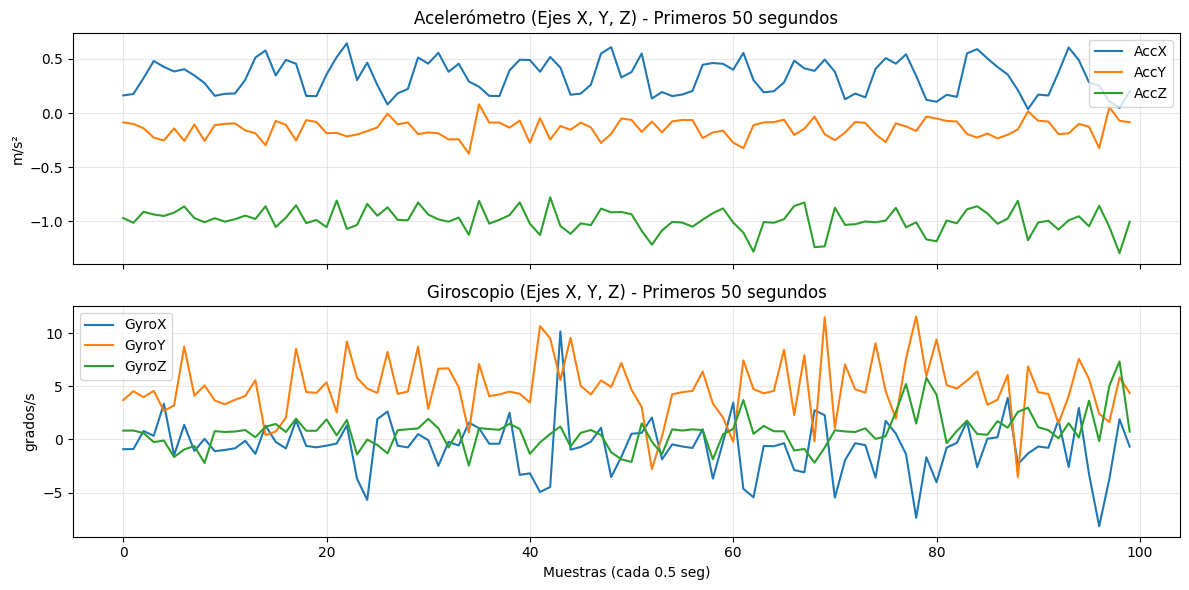

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

cols_acc = ['AccX', 'AccY', 'AccZ']   # Acelerómetro
cols_gyro = ['GyroX', 'GyroY', 'GyroZ'] # Giroscopio

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Gráfico1: Aceleración lineal (frenadas, aceleradas, baches)
muestra[cols_acc].plot(ax=axes[0], linewidth=1.5)
axes[0].set_title("Acelerómetro (Ejes X, Y, Z) - Primeros 50 segundos")
axes[0].set_ylabel("m/s²")
axes[0].grid(True, alpha=0.3)

# Gráfico2: Velocidad angular (giros, volantazos)
muestra[cols_gyro].plot(ax=axes[1], linewidth=1.5)
axes[1].set_title("Giroscopio (Ejes X, Y, Z) - Primeros 50 segundos")
axes[1].set_ylabel("grados/s")
axes[1].set_xlabel("Muestras (cada 0.5 seg)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

El acelerometro presenta las 3 variables X,Y,Z: AccX oscila en valores cercanos a 0.3, AccY cerca de -0.1 y AccZ cerca de -1.0. Hay variaciones a medida que pasa el tiempo representando acelerones y frenadas bruscas. Algo particular a resaltar es el eje z, si los autores hubieran convertido el dato a m/s2, AccZ oscilaría alrededor de -9,8, no de -1,0. Deduciendo esto, podemos decir que el acelerómetro trabaja en unidades de gravedad (g), no en m/s². Entonces, el eje AccZ oscila alrededor de -1 g en reposo, lo que indica que el sensor está montado invertido. Los valores de AccX (+0,35) y AccY (-0,15) reflejan una inclinación fija del dispositivo desde el inicio.

GyroZ nos servira para distinguir giros a derecha e izquierda, ya que registra la rotación sobre el eje vertical (valores de signo opuesto). En cambio, las aceleraciones y frenadas bruscas se reflejan principalmente en AccX o AccY, según la orientación del dispositivo. También podrian ayudar a detectar fuerzas laterales durante los giros.

La orientación del sensor debe considerarse al interpretar las variables y seleccionar atributos. GyroZ será clave para clasificar giros, mientras que los ejes del acelerómetro permitirán caracterizar aceleraciones, frenadas y fuerzas laterales.

Distribución de registros por clase en %

In [16]:
# Proporción de cada clase en datos crudos
print("Balance df_raw en %:")
print((df_raw['Target(Class)'].value_counts(normalize=True) * 100).round(2))

# Y en ventanas
print("\nBalance df_feat en %:")
print((df_feat['Target'].value_counts(normalize=True) * 100).round(2))

Balance df_raw en %:
Target(Class)
3    31.42
2    25.85
1    22.62
4    20.11
Name: proportion, dtype: float64

Balance df_feat en %:
Target
3    31.49
2    25.86
1    22.60
4    20.05
Name: proportion, dtype: float64


Distribución de clases: Las cuatro clases mantienen proporciones similares en ambos archivos (entre 20% y 31,5%). No existe un desbalance crítico, por lo que no sería necesario aplicar oversampling. Veremos si es optimo utilizar stratify (estratificada)

En df_raw la columna objetivo se llama Target(Class), mientras que en df_feat se llama Target.

A ver que pasa con df_feat:

In [17]:
# Ver nombres de las columnas generadas en df_feat
print(f"\nTotal de columnas en df_feat: {df_feat.shape[1]}")
print(list(df_feat.columns))


Total de columnas en df_feat: 61
['Target', 'AccMeanX', 'AccMeanY', 'AccMeanZ', 'AccCovX', 'AccCovY', 'AccCovZ', 'AccSkewX', 'AccSkewY', 'AccSkewZ', 'AccKurtX', 'AccKurtY', 'AccKurtZ', 'AccSumX', 'AccSumY', 'AccSumZ', 'AccMinX', 'AccMinY', 'AccMinZ', 'AccMaxX', 'AccMaxY', 'AccMaxZ', 'AccVarX', 'AccVarY', 'AccVarZ', 'AccMedianX', 'AccMedianY', 'AccMedianZ', 'AccStdX', 'AccStdY', 'AccStdZ', 'GyroMeanX', 'GyroMeanY', 'GyroMeanZ', 'GyroCovX', 'GyroCovY', 'GyroCovZ', 'GyroSkewX', 'GyroSkewY', 'GyroSkewZ', 'GyroSumX', 'GyroSumY', 'GyroSumZ', 'GyroKurtX', 'GyroKurtY', 'GyroKurtZ', 'GyroMinX', 'GyroMinY', 'GyroMinZ', 'GyroMaxX', 'GyroMaxY', 'GyroMaxZ', 'GyroVarX', 'GyroVarY', 'GyroVarZ', 'GyroMedianX', 'GyroMedianY', 'GyroMedianZ', 'GyroStdX', 'GyroStdY', 'GyroStdZ']


df_feat contiene 60 características, muchas aportan información similar. Por ejemplo, la varianza se obtiene elevando al cuadrado el desvío estándar y la suma depende del promedio y la cantidad de registros. Esto justifica evaluar la eliminación de atributos redundantes antes del modelado.

Para empezar, analizaremos solo 4 caracteristicas que considere basicas contra el target, con el fin de ver alguna relacion entre ellas y evitar a primera instancia un grafico super grande inentendible. 

1) AccMeanX y AccStdX (Aceleración hacia adelante/atrás): El eje X apunta a lo largo del auto, por lo que captura aceleraciones y frenadas. El promedio (Mean) busca detectar la dirección del empuje, mientras que el desvío estándar (Std) mide qué tan brusco o repentino fue el sacudón dentro de los 14 segundos.
2) GyroMeanZ y GyroStdZ (Giro del volante): El eje Z vertical mide cómo rota el auto visto desde arriba. El promedio (Mean) captura el sentido del giro (signo positivo o negativo para izquierda o derecha), y el desvío (Std) mide la intensidad de la curva.

Cruzarlas contra Target, permite comprobar visualmente si las 4 maniobras forman grupos separados antes de entrenar cualquier algoritmo.

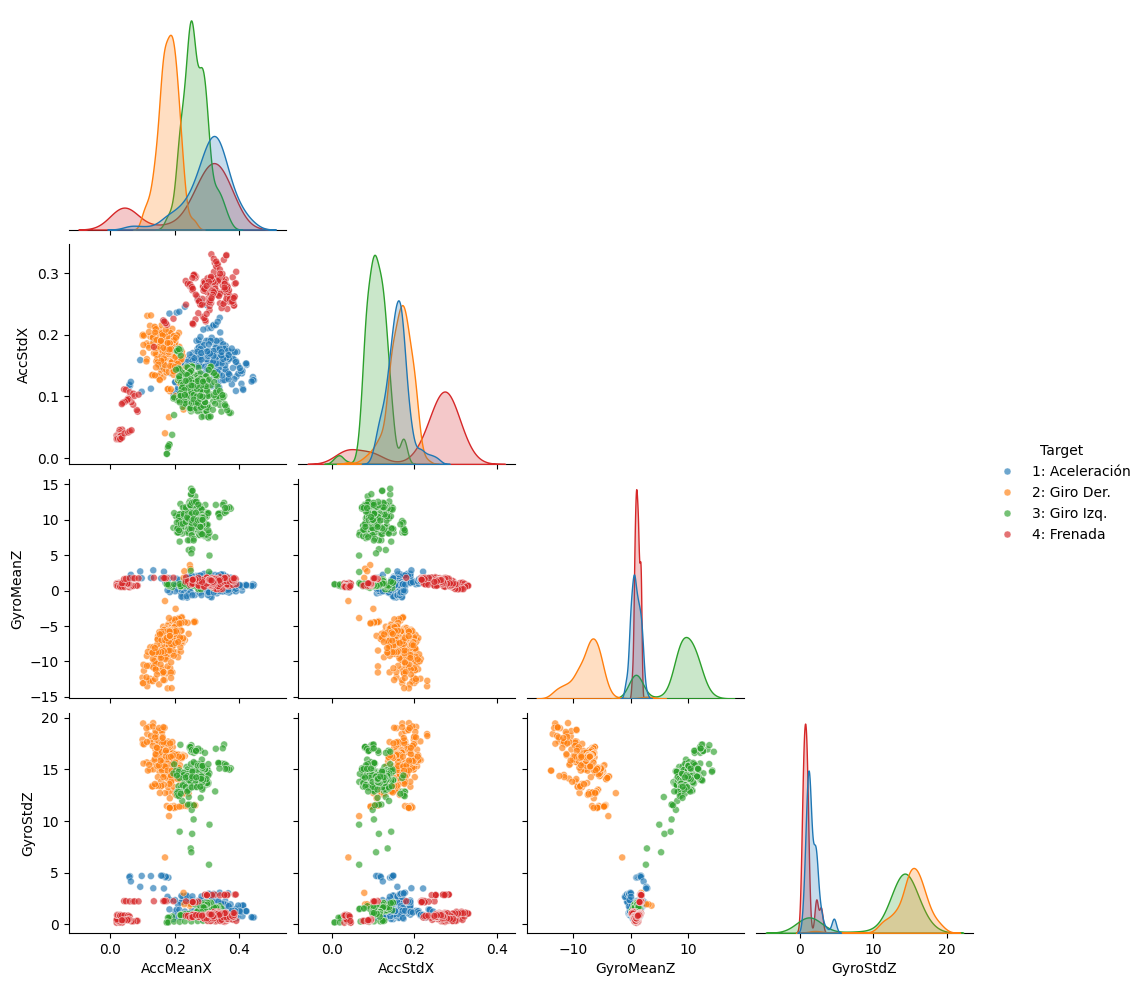

In [18]:
# Seleccionamos las 4 variables físicas clave + variable objetivo
cols_fisicas = ['AccMeanX', 'AccStdX', 'GyroMeanZ', 'GyroStdZ', 'Target']

# Nombres descriptivos para las clases
etiquetas = {
    1: '1: Aceleración',
    2: '2: Giro Der.',
    3: '3: Giro Izq.',
    4: '4: Frenada'
}

df_plot = df_feat[cols_fisicas].copy()
df_plot['Target'] = df_plot['Target'].map(etiquetas)

# Generamos el pairplot mostrando solamente la mitad inferior
feat_plot = sns.pairplot(
    df_plot,
    hue='Target',
    diag_kind='kde',
    plot_kws={'alpha': 0.65, 's': 25},
    corner=True
)

plt.show()

Se puede obvservar que:

- Los giros se separan limpiamente ya que GyroMeanZ divide los giros a la derecha (valores negativos) de los giros a la izquierda (valores positivos), dejando en el centro a las maniobras en línea recta.

- Dentro de una ventana de 14 segundos una frenada podria durar muy poco, entonces el promedio (AccMeanX) la camufla bastante y la mezcla con la aceleración. En cambio, al ver AccStdX se puede capturar ese cambio violento y logra despegar ambas clases.

- Las nubes de puntos forman grupos bien definidos pero con geometrías curvas (como esa "V" en el giroscopio), lo que justifica usar algoritmos como Random Forest, KNN o SVM en lugar de modelos lineales simples.

El pairplot anterior solo cubre 4 columnas y deja 56 sin revisar, por lo que usaremos otro metodo para abrir el abanico de posibilidades. De todos modos 60 columnas es una cantidad muy grande, por lo que en esta etapa de pre limpieza buscaremos reducir la cantidad sin perder informacion valiosa

In [19]:
# Seleccionamos 12 columnas que previamente consideramos redundantes (Sum y Var)
cols_redundantes = [
    col for col in df_feat.columns 
    if 'Sum' in col or 'Var' in col
]

# DataFrame depurado (Target + 48 atributos)
df_feat_reducido = df_feat.drop(columns=cols_redundantes)

print(f"Nueva dimensión: {df_feat_reducido.shape}")

Nueva dimensión: (1102, 49)


Se eliminaron 12 atributos redundantes y se conservaron los demás para evaluar cuáles aportan información útil:

1. Variables Sum: Se eliminaron porque, al tener todas las ventanas la misma cantidad de muestras, la suma depende directamente del promedio. Por lo tanto, no aportan información nueva.

2. Variables Var: Se eliminaron porque la varianza es el desvío estándar elevado al cuadrado. Se conservó Std porque es más fácil de interpretar y mantiene las unidades originales de los sensores.

3. Resto de los atributos: Se conservaron métricas como Median, Min, Max, Skew, Kurt y Cov porque describen diferentes aspectos de las señales. Su utilidad y posible redundancia se evaluarán mediante el análisis de correlaciones (profiling).

Pandas Profiling es una herramienta de Python que permite generar automáticamente un informe sobre un conjunto de datos dado, usando Pandas. Con unas pocas líneas de código, Pandas Profiling te analiza todas las columnas de un DataFrame, y te genera un reporte detallado sobre algunas de las estadísticas que nadie debería ignorar cuando empieza a estudiar un dataset. Ojo, igual. Aunque parezca un atajo (que lo es), no es una función que nos resuelva todo: nos da información que después tenemos que procesar nosotros, y además no nos da absolutamente todo lo que necesitamos. Es una ayuda muy buena, pero definitivamente no suficiente.

In [20]:
# Genera el reporte sobre el conjunto ya reducido y lo guardamos en HTML
from pathlib import Path

ruta_reporte = Path("../data/processed/eda_kaggle_feat.html")

# Solo generamos el reporte si no existe previamente
if not ruta_reporte.is_file():
    report = ProfileReport(
        df_feat_reducido,
        title="Auditoría EDA - Kaggle Features (14s) Depurado"
    )
    report.to_file(str(ruta_reporte))
    print("Reporte generado correctamente.")
else:
    print("El reporte ya existe. Se omite su generación.")

El reporte ya existe. Se omite su generación.


En el navegador pegar:
/home/matias-muller/Documents/Programacion/tp-ia-driving-behavior/data/processed/eda_kaggle_feat.html

Calidad de los datos:
- Las 1.102 ventanas están completas, por lo que no es necesario aplicar técnicas de imputación.
- Se identificaron 48 variables numéricas y una variable categórica (Target), listas para el procesamiento.

Relaciones y alertas
- Target presenta asociaciones con 17 características, lo que indica que existen patrones útiles para diferenciar las cuatro maniobras.
- Mean y Median muestran correlaciones altas porque ambas representan el valor central de la señal. También se observan relaciones entre Std y otras métricas de dispersión, que deberán evaluarse durante la selección de atributos.
- La correlación entre GyroZ y AccY es coherente con los giros: la rotación del vehículo se relaciona con las fuerzas laterales durante las curvas.
- Tener características con muchos valores únicos es normal en mediciones continuas. Los ceros de AccMinX representan apenas el 1,2% de los registros y no justifican eliminarlos automáticamente.

La ausencia de filas duplicadas descarta duplicados exactos, pero no garantiza que no existan ventanas temporales superpuestas. Las decisiones deberán confirmarse utilizando únicamente los datos de entrenamiento (X_train).

Hagamos un reporte sobre df_raw como para ir cerrando esta etapa

In [ ]:
# Genera el reporte sobre df_feat completo y lo guardamos en HTML 
ruta_reporte = Path("../data/processed/eda_kaggle_raw.html")

# Solo generamos el reporte si no existe previamente
if not ruta_reporte.is_file():
    report = ProfileReport(
        df_raw,
        title="Auditoría EDA - Kaggle Raw"
    )
    report.to_file(str(ruta_reporte))
    print("Reporte generado correctamente.")
else:
    print("El reporte ya existe. Se omite su generación.")

El reporte ya existe. Se omite su generación.


Todo se ve bastante normal, se pueden notar que las correlaciones no son muy fuertes entre las variables

Por ultimo, un ultimo analisis rapido sobre ambos df

In [22]:
import numpy as np
import pandas as pd

def auditar_calidad(df, nombre):
    filas, columnas = df.shape
    print(f"Auditoría: {nombre} ({filas} filas, {columnas} columnas)")

    # Valores nulos
    nulos = df.isna().sum() # Contamos los nulos por columna
    nulos = nulos[nulos > 0] # Filtramos solo las columnas con nulos

    print(f"Nulos encontrados:\n{nulos}" if not nulos.empty else "Nulos (NaN): 0")

    # Valores infinitos (solo columnas numéricas)
    num_df = df.select_dtypes(include='number') # Seleccionamos solo las columnas numéricas
    infinitos = np.isinf(num_df).sum() # Contamos los infinitos por columna
    infinitos = infinitos[infinitos > 0] # Filtramos solo las columnas con infinitos

    print(f"Infinitos encontrados:\n{infinitos}" if not infinitos.empty else "Infinitos (inf): 0")
    
    # Cadenas vacías o con espacios
    texto_df = df.select_dtypes(include=['object', 'string']) # Seleccionamos solo las columnas de texto
    vacios = texto_df.apply(
        lambda columna: columna.astype('string').str.strip().eq('').sum()
    ) # Contamos las cadenas vacías o con espacios por columna
    vacios = vacios[vacios > 0]

    print(f"Cadenas vacías o con espacios:\n{vacios}" if not vacios.empty else "Cadenas vacías o con espacios: 0")
    
    # Filas duplicadas
    duplicados = df.duplicated().sum() # Contamos las filas duplicadas
    porcentaje = duplicados / filas * 100 if filas > 0 else 0 # Calculamos el porcentaje de duplicados

    print(f"Filas duplicadas: {duplicados} ({porcentaje:.2f}%)\n")


# Auditamos ambos conjuntos de Kaggle
auditar_calidad(df_raw, "Kaggle Raw (2 Hz)")
auditar_calidad(df_feat, "Kaggle Features (14s)")

Auditoría: Kaggle Raw (2 Hz) (1114 filas, 7 columnas)
Nulos (NaN): 0
Infinitos (inf): 0
Cadenas vacías o con espacios: 0
Filas duplicadas: 0 (0.00%)

Auditoría: Kaggle Features (14s) (1102 filas, 61 columnas)
Nulos (NaN): 0
Infinitos (inf): 0
Cadenas vacías o con espacios: 0
Filas duplicadas: 0 (0.00%)



CIERRE DEL DIAGNOSTICO DATASET_KAGGLE

El dataset presenta una buena calidad estructural, sin valores faltantes, infinitos ni duplicados exactos. Sin embargo, se identificaron ciertas limitaciones que deben considerarse antes del modelado.
- No es necesario imputar valores ni eliminar filas por problemas de calidad.
- Se identificaron las unidades de los sensores (El acelerómetro trabaja en fuerzas g). 
- Se detectaron posibles irregularidades de instalación del sensor por su condicion inicial y oscilacion entre rangos distintos de 0.0, como la orientación invertida del acelerómetro y un posible sesgo en GyroY.
- Las cuatro maniobras agresivas están relativamente equilibradas (entre 20% y 31,5%), pero el dataset no contempla una clase de conducción normal.
- Preprocesamiento: Se eliminarán aquellas variables matemáticamente redundantes como Sum y Var. La selección de atributos restante y el escalado se realizarán utilizando únicamente los datos de entrenamiento.
- No se conservan marcas de tiempo ni identificadores de viajes, conductores o vehículos. Además, los registros están agrupados por clase. Por lo tanto, no es posible reconstruir los viajes originales ni evaluar de manera confiable la generalización del modelo a conductores desconocidos.

Conclusión final: El dataset de Kaggle es adecuado como punto de partida para estudiar y clasificar las cuatro maniobras agresivas. No obstante, sus limitaciones temporales y la ausencia de identificadores impiden realizar una evaluación completa de la generalización del modelo. Estas restricciones deberán tenerse presentes al diseñar el preprocesamiento, la validación y la interpretación de los resultados.

-------------------------------------------------------------------------------------------------------------------------

ANALISIS EXPLORATORIO DE DATOS - DATASET GITHUB

procederemos a analizar en profundidad la estructura de los archivos y que informacion aportan tanto sus columnas como sus filas

segun la fuente, los groundTruth.csv de cada uno de los 4 viajes contienen el tipo de maniobra y sus tiempos de inicio y fin.


En Kaggle ya venían separadas las señales crudas (df_raw) y las métricas resumidas (df_feat). En GitHub en cambio hay 4 carpetas de viajes (16, 17, 20 y 21) con los archivos separados por sensor.

Cargaremos únicamente las etiquetas del viaje 16 para testear, ver cómo vienen escritas las columnas y los datos

Veamos groundTruth.csv

In [23]:
ruta_v16 = "../data/raw/dataset_github/data/16"

# Cargamos etiquetas del viaje 16
gt_16 = pd.read_csv(f"{ruta_v16}/groundTruth.csv")

print("Columnas originales:", list(gt_16.columns))
display(gt_16.head())

Columnas originales: ['evento', ' inicio', ' fim']


,evento,inicio,fim
0,evento_nao_agressivo,2.0,6.5
1,curva_direita_agressiva,19.5,23.5
2,evento_nao_agressivo,30.0,33.5
3,curva_direita_agressiva,95.0,98.0
4,curva_esquerda_agressiva,247.0,251.5


In [24]:
gt_16.columns = gt_16.columns.str.strip()

In [25]:
list(gt_16.columns)

['evento', 'inicio', 'fim']

Vemos los eventos en brasilero, y ademas el inicio-fin de los viajes. Algunos tiempos estan bastante separados entre si.

Veamos ahora dentro del viaje 16, algunos indicadores del sensor:

In [26]:
# cargamos aceleración lineal y giroscopio
acc_16 = pd.read_csv(f"{ruta_v16}/aceleracaoLinear_terra.csv")
gyro_16 = pd.read_csv(f"{ruta_v16}/giroscopio_terra.csv")

In [27]:
# Auditamos ambos conjuntos
print(f"Filas aceleración lineal: {len(acc_16)} | Filas giroscopio: {len(gyro_16)}")

# Auditamos las columnas
print("\nAceleración Lineal (head): ")
display(acc_16.head())

print("\nGiroscopio (head): ")
display(gyro_16.head())

# Vemos las estadísticas descriptivas
print("\nAceleración Lineal (describe): ")
display(acc_16[['x', 'y', 'z']].describe().round(3))

print("\nGiroscopio (describe): ")
display(gyro_16[['x', 'y', 'z']].describe().round(3))

Filas aceleración lineal: 64645 | Filas giroscopio: 64645

Aceleración Lineal (head): 


,timestamp,uptimeNanos,x,y,z
0,14/05/2016 10:54:33,11537640270059,-0.161602,0.120174,-0.209893
1,14/05/2016 10:54:33,11537650128140,-0.122628,0.315638,-0.380996
2,14/05/2016 10:54:33,11537659894659,-0.178777,0.330181,-0.360696
3,14/05/2016 10:54:33,11537679549779,0.016043,0.038759,-0.278204
4,14/05/2016 10:54:33,11537699204899,0.141716,-0.162492,-0.049796



Giroscopio (head): 


,timestamp,uptimeNanos,x,y,z
0,14/05/2016 10:54:33,11537635386799,-0.070372,0.000844,0.029619
1,14/05/2016 10:54:33,11537645580604,-0.058695,0.009130,0.024406
2,14/05/2016 10:54:33,11537667280589,0.006625,-0.002283,-0.015018
3,14/05/2016 10:54:33,11537684829803,0.064933,0.033172,-0.040503
4,14/05/2016 10:54:33,11537704912208,0.039454,-0.013078,-0.007681



Aceleración Lineal (describe): 


,x,y,z
count,64645.000,64645.000,64645.000
mean,0.001,-0.005,-0.081
std,0.863,0.838,0.537
min,-6.822,-6.211,-5.677
25%,-0.458,-0.451,-0.318
50%,-0.015,-0.000,-0.095
75%,0.431,0.457,0.135
max,7.366,6.333,10.306



Giroscopio (describe): 


,x,y,z
count,64645.000,64645.000,64645.000
mean,0.003,-0.003,0.059
std,0.092,0.087,0.248
min,-1.179,-1.204,-1.324
25%,-0.042,-0.045,-0.049
50%,0.001,-0.002,0.021
75%,0.047,0.042,0.135
max,0.989,0.512,1.197


- Tenemos 64.645 filas en ambos archivos, a comparacion de los 1114 de Kaggle. Aca el celular grabo a aproximadamente a 50 Hz (lecturas por segundo).
- Se nota que a diferencia de Kaggle, los valores en la aceleracion entre min y max se equiparan mas a metros sobre segundo cuadrado, de hasta +-7 a 10 en los extremos, y las rotaciones cercanas a +-1,3 en radianes sobre segundos.
- El promedio de z en aceleracaolinear_terra esta cerca de 0 porque ya le restaron los 9,81 metros sobre segundos de la gravedad

Columnas que vemos en el head:
- timestamp: momento donde fue tomado el registro
- uptimeNanos: tiempo desde que el sensor comenzó a registrar
- X, Y y Z, los ejes 


In [28]:
acelerometro_16 = pd.read_csv(f"{ruta_v16}/acelerometro_terra.csv")
print("\nAcelerómetro (describe) : ")
display(acelerometro_16[['x', 'y', 'z']].describe().round(3))


Acelerómetro (describe) : 


,x,y,z
count,64645.000,64645.000,64645.000
mean,0.001,-0.005,9.725
std,0.863,0.838,0.537
min,-6.822,-6.211,4.130
25%,-0.458,-0.451,9.489
50%,-0.015,-0.000,9.712
75%,0.431,0.457,9.942
max,7.366,6.333,20.113


analizando el describe() del acelerometro, se observa que el promedio de z es 9,72 y el resto es idéntico al de la aceleracion lineal. Por ende, es bastante redundante este .csv

En el paso anterior miramos solo el viaje 16, una foto parcial del problema. Antes de gastar tiempo sincronizando señales de 50 Hz o decidiendo qué descartar, veremos en detalle la variable objetivo "evento".

Uniremos los cuatro archivos groundTruth.csv (viajes 16, 17, 20 y 21) en una única tabla de etiquetas.

In [29]:
ruta_base = "../data/raw/dataset_github/data"
viajes = ["16", "17", "20", "21"]

# Leemos y apilamos el groundTruth.csv de los 4 viajes
lista_gt = []
for viaje in viajes:
    df_temp = pd.read_csv(f"{ruta_base}/{viaje}/groundTruth.csv")
    df_temp.columns = df_temp.columns.str.strip()  #Quitamos espacios en ' inicio' y ' fim'
    df_temp["viaje"] = viaje
    lista_gt.append(df_temp)

# Concatenamos todos los DataFrames en uno solo
df_gt = pd.concat(lista_gt, ignore_index=True)

Analicemos las maniobras de cada archivo entre si

In [ ]:
# Calculamos la duración real de cada maniobra en segundos
df_gt["duracion_s"] = df_gt["fim"] - df_gt["inicio"]

# Cantidad y duración por tipo de maniobra. se usan variables estadisticas para resumir la información de cada maniobra
print(f"Total de eventos etiquetados: {len(df_gt)}\n")
display(df_gt.groupby("evento")["duracion_s"].agg(["count", "mean", "min", "max"]).round(2))

# Tabla cruzada: qué maniobras aparecen en cada viaje
print("\nDistribución de eventos por viaje: ")
display(pd.crosstab(df_gt["viaje"], df_gt["evento"], margins=True))

Total de eventos etiquetados: 69



,count,mean,min,max
evento,,,,
aceleracao_agressiva,12,3.60,2.4,4.9
curva_direita_agressiva,11,3.47,3.0,4.5
curva_esquerda_agressiva,11,3.47,2.8,4.5
evento_nao_agressivo,14,3.54,2.1,4.5
freada_agressiva,12,2.39,1.9,3.7
troca_faixa_direita_agressiva,5,2.22,1.9,2.5
troca_faixa_esquerda_agressiva,4,2.10,1.6,2.4



Distribución de eventos por viaje: 


evento,aceleracao_agressiva,curva_direita_agressiva,curva_esquerda_agressiva,evento_nao_agressivo,freada_agressiva,troca_faixa_direita_agressiva,troca_faixa_esquerda_agressiva,All
viaje,,,,,,,,
16,0,5,5,3,0,3,0,16
17,6,0,0,0,6,2,0,14
20,0,6,6,5,0,0,0,17
21,6,0,0,6,6,0,4,22
All,12,11,11,14,12,5,4,69


<Axes: xlabel='count', ylabel='evento'>

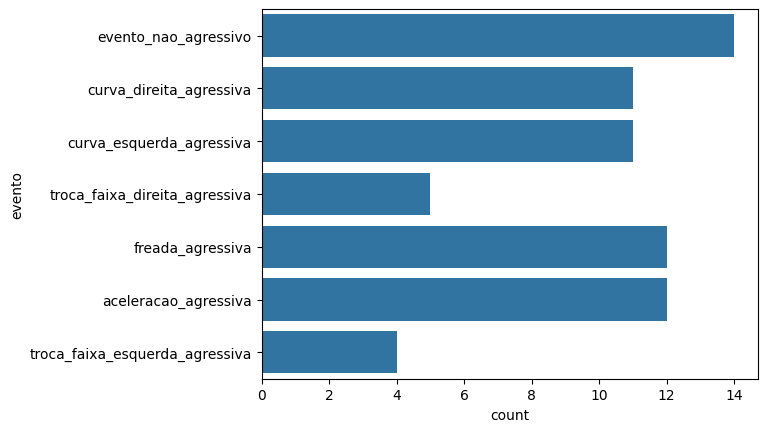

In [31]:
sns.countplot(data=df_gt, y="evento")

- El dataset tiene 69 eventos repartidos en 7 categorías (aparece aceleracao_agressiva, que faltaba nombrar en el README). Mientras las 5 clases principales tienen entre 11 y 14 ejemplos, los cambios de carril (troca_faixa_direita y troca_faixa_esquerda) tienen apenas 5 y 4 casos en total. Hay una limitacion al contar con tan pocos ejemplos, cualquier modelo podria sufrir para aprender/predecir esas dos clases y habrá que evaluar métricas como F1-macro o incluso discutir si conviene agruparlas o filtrarlas en el modelado.   
- Las frenadas y cambios de carril segun la tabla duran en promedio poco más de 2 segundos, y los giros o aceleraciones alrededor de 3,5 segundos. Esto nos daria la escala temporal para diseñar las ventanas más adelante (recordemos como en Kaggle una ventana de 7 segundos mezclaba pedazos de eventos).
- La tabla cruzada muestra que los viajes no son intercambiables, miremos esto! los viajes 16 y 20 concentran los giros (cero aceleraciones y cero frenadas), mientras que 17 y 21 concentran las aceleraciones y frenadas (cero giros). Además, los 4 cambios de carril a la izquierda están todos en el viaje 21. La limitacion radica en que no podremos dejar un viaje suelto como conjunto de prueba, sin quedarnos sin clases completas en test. Los 4 viajes funcionan en la práctica como 2 sesiones completas (16+17 y 20+21).
- Si sumaramos df_gt["duracion_s"].sum(), notariamos que los 69 eventos ocupan apenas ~3,6 minutos frente a los ~51 minutos totales de grabación. El resto del viaje no tiene etiqueta y no debemos asumir a ciegas que todo ese tiempo restante es conducción "normal".

Entonces vimos que aceleracaoLinear_terra y giroscopio_terra tienen exactamente la misma cantidad de filas (64.645). 
Antes de incorporar los otros dos archivos, comprobaremos si acelerometro_terra aporta información distinta a aceleracaoLinear_terra o si es redundante. Ademas, si campoMagnetico_terra trae problemas de calidad (duplicados, variables constantes o distinta frecuencia).

In [32]:
ruta_v16 = "../data/raw/dataset_github/data/16"

# cargamos las rutas de los archivos de acelerómetro y campo magnético
acc_total_16 = pd.read_csv(f"{ruta_v16}/acelerometro_terra.csv")
mag_16 = pd.read_csv(f"{ruta_v16}/campoMagnetico_terra.csv")

In [33]:
# Acelerómetro Total vs. Aceleración Lineal
print(f"Filas acelerómetro total: {len(acc_total_16)} | Filas aceleración lineal: {len(acc_16)}")
diferencia = acc_total_16[['x', 'y', 'z']] - acc_16[['x', 'y', 'z']]

print("\nDiferencia entre acelerometro_terra - aceleracaoLinear_terra: ")
display(diferencia.describe().loc[['mean', 'std', 'min', 'max']].round(5))

Filas acelerómetro total: 64645 | Filas aceleración lineal: 64645

Diferencia entre acelerometro_terra - aceleracaoLinear_terra: 


,x,y,z
mean,0.0,-0.0,9.80665
std,0.0,0.0,0.00000
min,-0.0,-0.0,9.80665
max,0.0,0.0,9.80665


Al restar ambos archivos, la diferencia en x e y es 0.0 y en z es exactamente 9.80665 con desvío estándar 0.0. Demostrando matemáticamente que el acelerómetro total y la aceleración lineal son la misma señal desplazada por una constante "la gravedad terrestre". Conservaremos solamente aceleracaoLinear_terra 

In [34]:
# Analizamos el Magnetómetro (volumen, estadísticas y duplicados)
print(f"\nMagnetómetro ({len(mag_16)} filas)")
print("Nulos totales:", mag_16.isna().sum().sum())
print("Filas duplicadas:", mag_16.duplicated().sum())
print("Marcas de tiempo (uptimeNanos) repetidas:", mag_16['uptimeNanos'].duplicated().sum())
display(mag_16[['x', 'y', 'z']].describe().loc[['mean', 'std', 'min', 'max']].round(3))


Magnetómetro (128956 filas)
Nulos totales: 0
Filas duplicadas: 2
Marcas de tiempo (uptimeNanos) repetidas: 64311


,x,y,z
mean,-0.0,28.097,-10.172
std,0.0,11.352,2.914
min,-0.0,9.963,-23.015
max,0.0,43.686,3.118


Este archivo presenta tres problemas concretos:
- El eje x tiene media, mínimo, máximo y desvío iguales a 0.0 (porque el sistema _terra alinea el eje y con el Norte magnético). 
- Tiene casi el doble de filas (128.956, osea aprox 101 Hz), filas exactamente duplicadas y más de 64.000 marcas uptimeNanos repetidas. 
- Entonces integrarlo obligaría a eliminar varios duplicados y remuestrear señales solo para medir la orientación geográfica respecto al Norte, algo que no describe la brusquedad de una maniobra.

Tacticamente seria mejor quedarnos solo con aceleracaoLinear_terra y giroscopio_terra ya que simplifica mucho el pipeline (ambos corren cercano a 50,9 Hz con 0 nulos y 0 duplicados). El tema es que al descartar la brújula perdemos la referencia directa de hacia qué punto cardinal apuntaba el auto, detalle que vamos a comprobar físicamente en el próximo paso al graficar las maniobra

Debemos pasar de nanosegundos a segundos del viaje, sabemos que groundTruth.csv marca el inicio y fim en segundos desde que arrancó la grabación, mientras que los sensores guardan uptimeNanos, los nanosegundos desde que se encendió el celular. Restando firstCollectionUptimeNanos (el instante cero guardado en viagem.json) y dividiendo por $10^9$, ambos archivos quedan en el mismo reloj.   

In [37]:
# Guardamos en t0 el instante inicial desde viagem.json
import json

with open(f"{ruta_v16}/viagem.json", "r") as f:
    t0 = json.load(f)["firstCollectionUptimeNanos"]

In [38]:
# Pasamos de uptimeNanos a segundos desde el inicio del viaje
acc_16["tiempo_s"] = (acc_16["uptimeNanos"] - t0) / 1e9
gyro_16["tiempo_s"] = (gyro_16["uptimeNanos"] - t0) / 1e9

In [39]:
# Calculamos la magnitud horizontal de aceleración (combinar X e Y en una sola curva)
acc_16["mag_xy"] = np.sqrt(acc_16["x"]**2 + acc_16["y"]**2)

In [40]:
# Filtramos los primeros 40 segundos
acc_tramo = acc_16[acc_16["tiempo_s"] <= 40]
gyro_tramo = gyro_16[gyro_16["tiempo_s"] <= 40]

In [41]:
# Filtramos el groundTruth para los primeros 40 segundos
gt_16.columns = gt_16.columns.str.strip()
gt_tramo = gt_16[gt_16["fim"] <= 40]

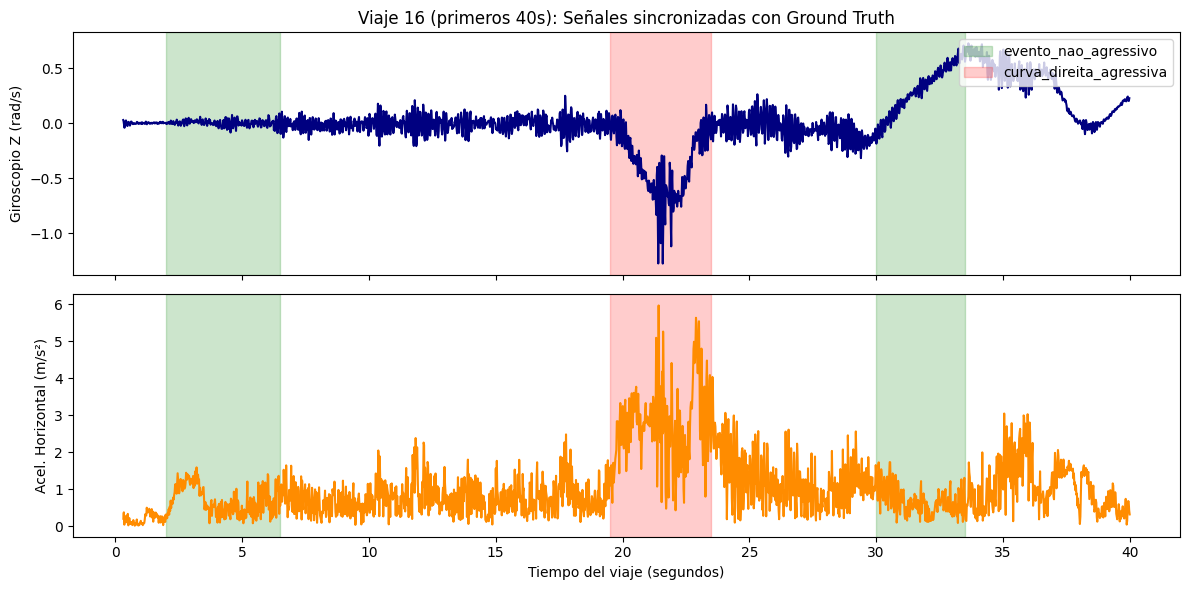

In [42]:
# Graficamos ambas señales y pintamos las franjas de groundTruth
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(gyro_tramo["tiempo_s"], gyro_tramo["z"], color="navy")
axes[0].set_ylabel("Giroscopio Z (rad/s)")
axes[0].set_title("Viaje 16 (primeros 40s): Señales sincronizadas con Ground Truth")

axes[1].plot(acc_tramo["tiempo_s"], acc_tramo["mag_xy"], color="darkorange")
axes[1].set_ylabel("Acel. Horizontal (m/s²)")
axes[1].set_xlabel("Tiempo del viaje (segundos)")

# Sombreamos cada evento: verde = normal, rojo = agresivo
for _, fila in gt_tramo.iterrows():
    color = "green" if fila["evento"] == "evento_nao_agressivo" else "red"
    for ax in axes:
        ax.axvspan(fila["inicio"], fila["fim"], color=color, alpha=0.2, label=fila["evento"])

# Evitamos etiquetas repetidas en la leyenda
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[0].legend(by_label.values(), by_label.keys(), loc="upper right")

plt.tight_layout()
plt.show()

- A primera vista observamos un pico pronunciado de rotación en Giroscopio Z y el empuje lateral en Acel. Horizontal, cerca de los 20 segundos. Comprobamos ademas que se alinearon bastante bien los sensores con el video.
- Se puede ver que dentro de las franjas verdes (que corresponden a evento_nao_agressivo), las curvas se mantienen bajas y suaves, mientras que en la franja roja (curva_direita_agressiva) la energía de ambos sensores se dispara. Esto onfirma que las señales crudas tienen información real para clasificar.
- Fijarse que en los tramos sin pintar, aunque no tienen etiqueta en groundTruth.csv, aparecen ciertas vibraciones o maniobras cotidianas no registradas. Por eso hubiera sido un error asumir automáticamente que todo el fondo blanco era "conducción normal" sin antes filtrarlo o revisarlo.

Para cerrar el análisis exploratorio y evaluar si las señales permiten distinguir las 7 maniobras, integramos los cuatro recorridos en una única tabla resumen de 69 eventos etiquetados. Esta combinación sera necesaria por los siguientes motivos.

1) Los viajes están distribuidos según el tipo de maniobra realizada, los recorridos 16 y 20 concentran los giros, mientras que 17 y 21 concentran las aceleraciones y frenadas (y los cambios de carril aparecen repartidos). Analizar un solo viaje dejaría clases enteras fuera de la comparación.
2) En lugar de concatenar más de 150.000 registros crudos (más del 90% corresponde a tramos sin etiquetar) sincronizaremos cada viaje por separado usando su propio firstCollectionUptimeNanos (viagem.json) y recortamos únicamente los intervalos validados en groundTruth.csv
3) Resumiremos cada maniobra mediante sus picos de "aceleración horizontal (mag_xy)" y "velocidad de giro (|gyro_z|)" para convertir las series temporales (que ya sabemos que aprox a 50 Hz) en una buena tabla comparable, permitiéndonos observar de forma simple qué clases se separan y dónde existen solapamientos.

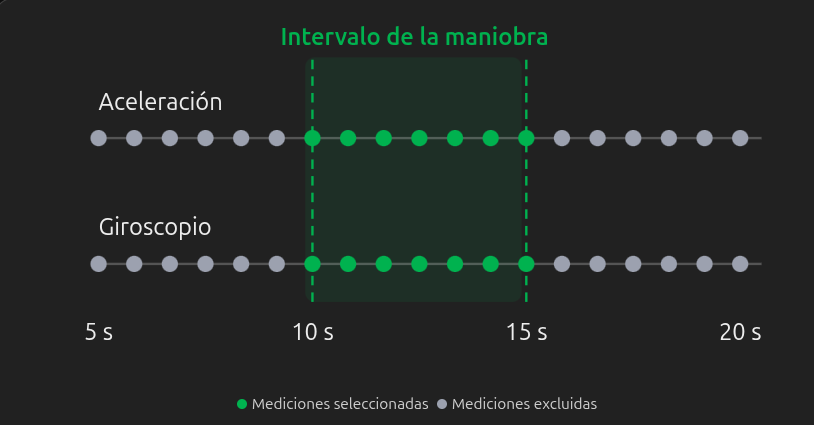

enves de usar la aceleracion lineal y el giroscopio z solo como estan, usaremos medidas estadisticas para captar mayores desplazamientos

- acc_mag_max: la fuerza máxima en el plano horizontal ($\sqrt{x^2 + y^2}$) durante la maniobra. Magnitud horizontal
- gyro_z_abs_max: Representa la máxima velocidad de rotación, independientemente del sentido de giro. Por eso se utiliza el valor absoluto (abs())
- gyro_z_mean: promedio de giro en z. Conserva el signo de las mediciones, permitiendo distinguir el sentido predominante de rotación (izquierda o derecha, según la orientación de los ejes del sensor).

por ejemplo para imaginar visualmente:

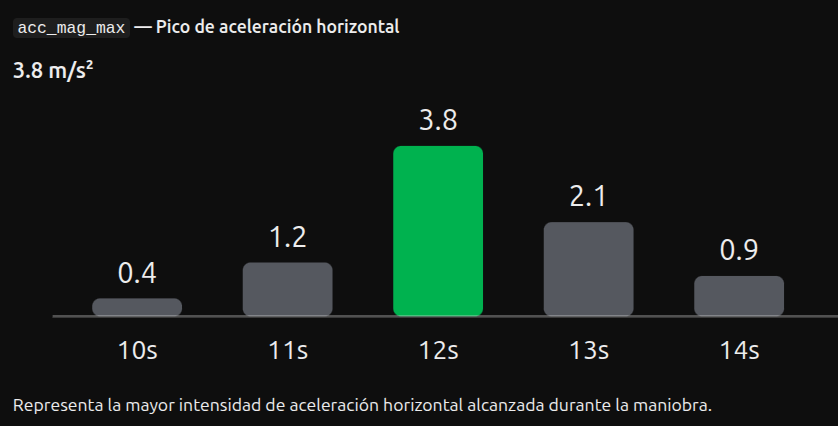

La mediana es el valor central de las observaciones ordenadas. A diferencia de la media, es menos sensible a valores extremos. Agruparemos las maniobras por su tipo y calcularemos la mediana de cada característica numérica, con el objetivo de identificar si existen diferencias físicas entre las clases de maniobras:

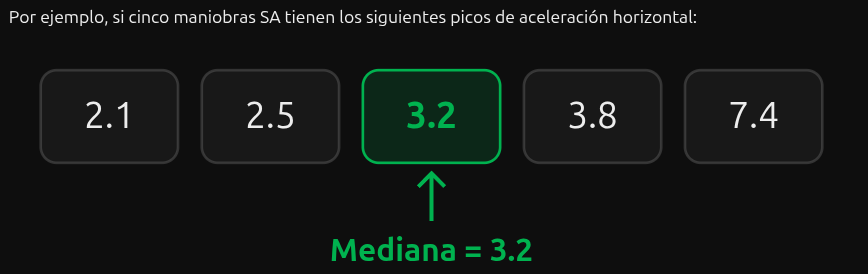

se está calculando la mediana de los picos de cada maniobra, no la mediana de todas las mediciones originales del sensor.

In [43]:
ruta_base = "../data/raw/dataset_github/data"
viajes = ["16", "17", "20", "21"]

In [48]:
from pathlib import Path

filas = []

# Iteramos sobre cada viaje y extraemos las características de cada maniobra
for v in viajes:
    ruta = Path(ruta_base) / v
    
    # Guardamos en t0 el instante inicial desde viagem.json
    with open(ruta / "viagem.json") as f:
        t0 = json.load(f)["firstCollectionUptimeNanos"]

    # Cargamos el groundTruth.csv de este viaje
    gt = pd.read_csv(ruta / "groundTruth.csv")
    gt.columns = gt.columns.str.strip()
    
    # Cargamos aceleración lineal y giroscopio
    acc = pd.read_csv(ruta / "aceleracaoLinear_terra.csv")
    gyro = pd.read_csv(ruta / "giroscopio_terra.csv")

    # Convertimos los tiempos a segundos desde el inicio del viaje
    for sensor in (acc, gyro):
        sensor["tiempo_s"] = (sensor["uptimeNanos"] - t0) / 1e9
    
    # Calculamos la magnitud horizontal de aceleración (combinar X e Y en una sola curva) tmb llamada hipotenusa.
    acc["mag_xy"] = np.hypot(acc["x"], acc["y"])

    # Extraemos las características de cada maniobra para este viaje
    for ev in gt.itertuples(index=False):
        seg_acc = acc.loc[acc["tiempo_s"].between(ev.inicio, ev.fim), "mag_xy"]
        seg_gyro = gyro.loc[gyro["tiempo_s"].between(ev.inicio, ev.fim), "z"]
        
        # En lugar de guardar todas las mediciones de la maniobra, calculamos tres valores representativos.    
        filas.append({
            "viaje": v,
            "evento": ev.evento,
            "acc_mag_max": seg_acc.max(), # Pico de aceleración horizontal
            "gyro_z_abs_max": seg_gyro.abs().max(), # Pico de giro en Z
            "gyro_z_mean": seg_gyro.mean() # Promedio de giro en Z
        })

# Creamos un DataFrame con todas las características extraídas
df_eventos = pd.DataFrame(filas)

# agrupa las maniobras por su tipo y calcula la mediana de cada característica numérica
# permitiendo comparar el comportamiento físico típico de cada clase
display(df_eventos.groupby("evento").median(numeric_only=True).round(2))

,acc_mag_max,gyro_z_abs_max,gyro_z_mean
evento,,,
aceleracao_agressiva,4.15,0.22,-0.01
curva_direita_agressiva,7.16,1.24,-0.44
curva_esquerda_agressiva,6.22,1.12,0.42
evento_nao_agressivo,2.70,0.40,-0.00
freada_agressiva,5.69,0.17,-0.00
troca_faixa_direita_agressiva,6.43,0.52,-0.01
troca_faixa_esquerda_agressiva,9.81,0.74,0.02


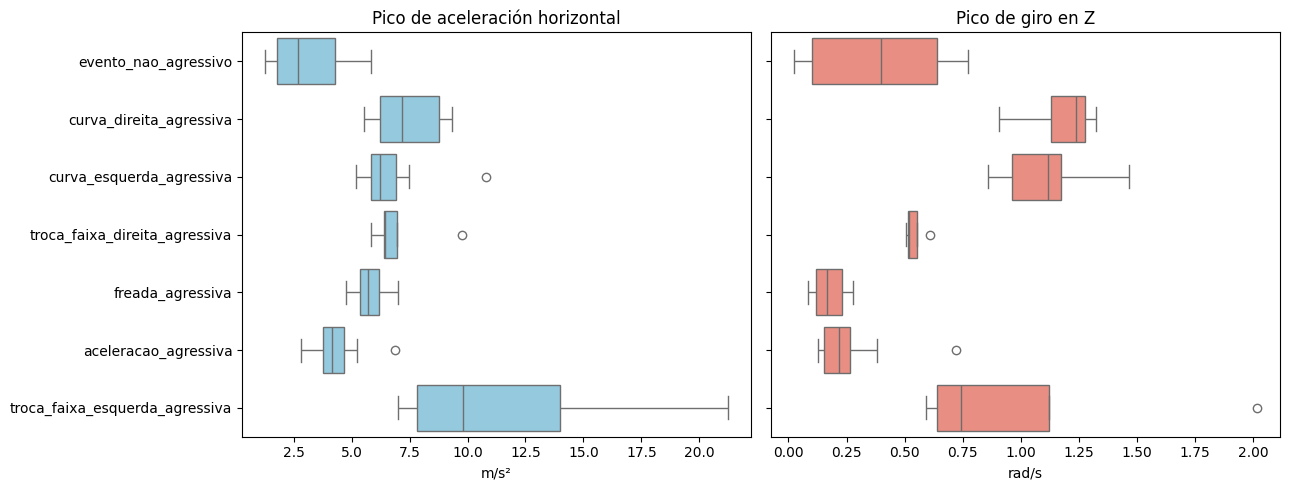

In [47]:
# Visualización
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

graficos = [
    ("acc_mag_max", "Pico de aceleración horizontal", "m/s²", "skyblue"),
    ("gyro_z_abs_max", "Pico de giro en Z", "rad/s", "salmon")
]

# Creamos un boxplot para cada variable, comparando los eventos agresivos vs. no agresivos
for ax, (variable, titulo, unidad, color) in zip(axes, graficos):
    sns.boxplot(data=df_eventos, x=variable, y="evento", ax=ax, color=color)
    ax.set(title=titulo, xlabel=unidad, ylabel="")

plt.tight_layout()
plt.show()

Reflexión de cierre del EDA de GitHub

- Giros agresivos: son las maniobras más fáciles de distinguir. En el gráfico derecho, ambas curvas superan los 0,80 rad/s sin superponerse con las demás categorías. Además, el signo del giro promedio (-0,44 frente a +0,42) permite diferenciar derecha de izquierda.

- Frenadas y aceleraciones: en el gráfico derecho presentan poca rotación (0,17 y 0,22 rad/s), propia de maniobras en línea recta. En el gráfico izquierdo, sus magnitudes de aceleración son relativamente cercanas (4,15 y 5,69 m/s²). Dado que la magnitud horizontal no conserva el sentido de la aceleración, distinguir ambas clases utilizando únicamente estas variables podría resultar difícil.

- Conducción no agresiva: en el gráfico izquierdo presenta la menor mediana de aceleración (2,50 m/s²), mientras que en el derecho muestra una amplia dispersión del giro, esto es coherente por incluir tanto desplazamientos rectos como curvas suaves. Sin embargo, algunos valores de aceleración alcanzan casi los 6 m/s², superponiéndose con maniobras agresivas.

- Cambios de carril: el cambio hacia la derecha presenta una rotación intermedia (0,50 rad/s) y una aceleración elevada (cerca de 6,50 m/s²). En cambio, hacia la izquierda se observa una gran dispersión, con aceleraciones superiores a 20 m/s² y un valor atípico de rotación de 2,01 rad/s. Al contar con solo 4 eventos, estos valores extremos pueden distorsionar la interpretación de la categoría.

Conclusión: la aceleración horizontal y la rotación sobre el eje Z son variables útiles para distinguir determinadas maniobras, especialmente los giros. Sin embargo, la superposición entre categorías, la pérdida de información direccional y la escasez de algunos eventos evidencian la necesidad de incorporar características adicionales para mejorar la clasificación del modelo.

A tener en cuenta para el preprocesamiento:

El análisis exploratorio permite justificar dos decisiones para la siguiente etapa:

- Extracción de características adicionales: los picos máximos resultan insuficientes para diferenciar algunas maniobras. Será necesario incorporar otras características de cada ventana, como la media, el desvío estándar, la información direccional y la evolución temporal de las señales.
- Tratamiento de clases minoritarias y valores extremos: la escasez de eventos de cambio de carril (4 y 5 casos) y la presencia de valores atípicos requieren evaluar métodos de escalado robustos y diseñar cuidadosamente la separación entre entrenamiento y prueba, evitando la fuga de datos y considerando la distribución de las clases por recorrido.